In [1]:
import torch
from torchvision import datasets
from torchvision.transforms import ToTensor
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
import matplotlib.pyplot as plt
import numpy as np
import pathlib
from torchvision.datasets import ImageFolder
from torchvision.transforms import Compose, Resize, ToTensor
from torch.utils.data import Subset
from torchviz import make_dot

In [2]:
pathToModels = pathlib.Path("models")
pathToData = pathlib.Path("data")
BATCH_SIZE = 64
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
TRASNFORM = Compose([
    Resize((224, 224)),
    ToTensor()
])

In [11]:
trainDataset = ImageFolder(
    root=pathToData / 'dogsVsCats/train',
    transform=TRASNFORM
)
testDataset = ImageFolder(
    root=pathToData / 'dogsVsCats/test',
    transform=TRASNFORM
)
trainDataset = Subset(trainDataset, 
                      list(range(0, 2000)) + list(range(12500, 14500)))
testDataset = Subset(testDataset, 
                     list(range(0, 1000)) + list(range(2500, 3500)))
trainLoader = torch.utils.data.DataLoader(
    trainDataset,
    batch_size=BATCH_SIZE,
    shuffle=True
)
testLoader = torch.utils.data.DataLoader(
    testDataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

In [4]:
# fig, axs = plt.subplots(2, 1, figsize=(10, 8)) 

# trainCounts = np.bincount([y for _, y in trainDataset])
# axs[0].bar(range(len(trainCounts)), trainCounts)
# axs[0].set_xticks(range(len(trainCounts)))

# testCounts = np.bincount([y for _, y in testDataset])
# axs[1].bar(range(len(testCounts)), testCounts)
# axs[1].set_xticks(range(len(testCounts)))

# plt.show()

In [5]:
from utils import *

In [6]:
import torch
import torch.nn as nn
from torchvision import models

class dogsVsCatsModel(nn.Module):
    def __init__(self, pretrained=True, freeze_features=True):
        super(dogsVsCatsModel, self).__init__()
        
        self.mobilenet = models.mobilenet_v3_small(pretrained=pretrained)
        
        if freeze_features:
            for param in self.mobilenet.features.parameters():
                param.requires_grad = False
        
        self.mobilenet.classifier = nn.Sequential(
            nn.Dropout(0.2),
            nn.Linear(576, 2)
        )
    
    def forward(self, x):
        return self.mobilenet(x)

In [7]:
model = dogsVsCatsModel().to(DEVICE)
model.mobilenet.features[12][0]

/home/jakub/Desktop/inz/algorythms/.venv/lib/python3.12/site-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/home/jakub/Desktop/inz/algorythms/.venv/lib/python3.12/site-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=MobileNet_V3_Small_Weights.IMAGENET1K_V1`. You can also use `weights=MobileNet_V3_Small_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


Conv2d(96, 576, kernel_size=(1, 1), stride=(1, 1), bias=False)

In [8]:
import os
os.listdir('./models/dogsVsCatsMobileNet/')

['best_model.pth', 'model.py']

In [9]:
model = dogsVsCatsModel().to(DEVICE)

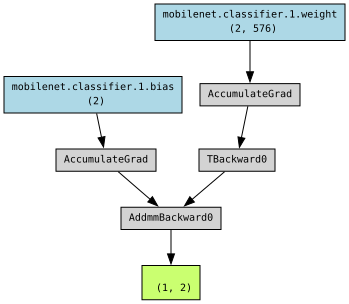

In [10]:
make_dot(model(torch.randn(1, 3, 224, 224)), params=dict(model.named_parameters()), show_attrs=False, show_saved=False)

In [ ]:
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)
model = train(model, trainLoader, testLoader, optimizer, criterion, DEVICE, 5, 'dogsVsCatsMobileNet')

Epoch 1/5 - Train Loss: 0.0068, Train Accuracy: 0.8235 - Test Loss: 0.0046, Test Accuracy: 0.9090
Epoch 2/5 - Train Loss: 0.0042, Train Accuracy: 0.9097 - Test Loss: 0.0042, Test Accuracy: 0.9050
Epoch 3/5 - Train Loss: 0.0036, Train Accuracy: 0.9147 - Test Loss: 0.0042, Test Accuracy: 0.9005
Epoch 4/5 - Train Loss: 0.0034, Train Accuracy: 0.9157 - Test Loss: 0.0038, Test Accuracy: 0.9085
Epoch 5/5 - Train Loss: 0.0032, Train Accuracy: 0.9243 - Test Loss: 0.0034, Test Accuracy: 0.9225
